# Harbor House Café — ¿El sentimiento escrito coincide con el promedio de 4.5★?

> 🇬🇧 **English version:** [`explore.ipynb`](explore.ipynb) (es el entregable principal). Este notebook tiene el mismo código y los mismos resultados, con la narrativa en español. Las etiquetas de los gráficos y de los datos (`Positive`, `Neutral`, `Negative`) se mantienen en inglés para que ambos notebooks sean idénticos en código.

**Mapa del notebook:** 1 Objetivos → 2 Exploración (EDA) → 3 Insights y limpieza → 4 Plan de acción y modelo → 5 Inferencia → 6 Desglose vs 4.5★ → 7 Falsos negativos → 8 Revisión manual → 9 Conclusiones

## 1. Objetivos

El cliente (Harbor House Café) recibirá **500 reseñas escritas** la próxima semana. Su puntuación media es de **4.5 / 5 estrellas**. La account manager pidió tres cosas, en términos simples:

1. **¿Cuántas reseñas *se leen* como positivas, neutrales o negativas?**
2. **¿Esa distribución coincide con el promedio de 4.5★?**
3. **Si hay diferencia, ¿de dónde viene?**, antes de ponerla frente al cliente.

Las respondemos con un modelo de sentimiento preentrenado (sin entrenar nada) y, sobre todo, comprobando en qué casos ese modelo es fiable.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # cosmetic tqdm notice

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Works whether the notebook is run from the repo root or from src/
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from utils import BAND_ORDER, MODEL_NAME, MODEL_REVISION, load_classifier, predict, to_band

RAW_PATH = ROOT / "data" / "raw" / "reviews.csv"
SEED = 42  # fixed seed -> every random sample in this notebook is reproducible

pd.set_option("display.max_colwidth", 220)
sns.set_theme(style="whitegrid")
BAND_COLORS = {"Negative": "#d1495b", "Neutral": "#9aa0a6", "Positive": "#2e8b57"}

## 2. Exploración (EDA)

Antes de usar ningún modelo, conocemos los datos: tamaño, tipos, huecos, cómo se reparten las estrellas y cómo son los textos.

In [2]:
df = pd.read_csv(RAW_PATH, encoding="utf-8")
print("Shape:", df.shape)
print(df.dtypes.to_string())
df.head()

Shape: (500, 3)
review_id      int64
rating         int64
review_text      str


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


500 filas y las tres columnas esperadas. `rating` es un entero y `review_text` es texto. Siguiente paso: valores faltantes y duplicados.

In [3]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nEmpty texts:", (df["review_text"].str.strip() == "").sum())
print("Duplicated review_id:", df["review_id"].duplicated().sum())
print("Duplicated review_text:", df["review_text"].duplicated().sum())

dups = df[df["review_text"].duplicated(keep=False)].sort_values("review_text")
print("\nDo duplicated texts share the same rating?",
      (dups.groupby("review_text")["rating"].nunique() == 1).all())
dups[["review_id", "rating", "review_text"]].head(6)

Missing values per column:
review_id      0
rating         0
review_text    0

Empty texts: 0
Duplicated review_id: 0
Duplicated review_text: 7

Do duplicated texts share the same rating? True


,review_id,rating,review_text
50,51,4,"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!"
112,113,4,"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!"
176,177,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
291,292,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.
483,484,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.


No hay valores faltantes ni vacíos. Hay 7 textos repetidos, pero cada uno tiene su propio `review_id` y la misma puntuación. Parecen clientes distintos que escribieron reseñas cortas muy parecidas, no errores de carga (en la sección 3 decidimos qué hacer con ellos).

Ahora, el núcleo de la pregunta de negocio: **¿cómo se construye el promedio de 4.5?**

,reviews,%
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


Average rating: 4.50


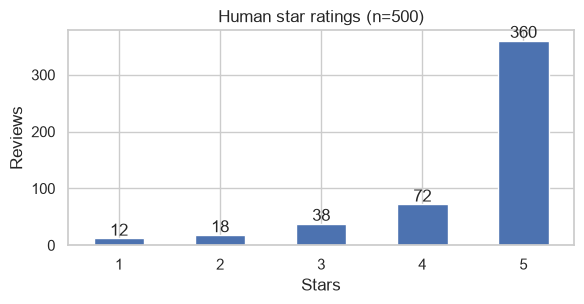

In [4]:
rating_counts = df["rating"].value_counts().sort_index()
rating_pct = (rating_counts / len(df) * 100).round(1)
display(pd.DataFrame({"reviews": rating_counts, "%": rating_pct}))
print(f"Average rating: {df['rating'].mean():.2f}")

ax = rating_counts.plot(kind="bar", color="#4c72b0", figsize=(6, 3.2), rot=0)
ax.set(title="Human star ratings (n=500)", xlabel="Stars", ylabel="Reviews")
for i, v in enumerate(rating_counts):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout(); plt.show()

El promedio de 4.5 es real (4.50) y está muy **concentrado arriba**: el 72% son reseñas de 5★ y solo el 6% de 1–2★. Si aplicamos el mapeo del proyecto a las estrellas humanas, obtenemos nuestra **distribución de referencia**: 86.4% positivas (4–5★), 7.6% neutrales (3★) y 6.0% negativas (1–2★). Eso es lo que significa "coincidir con 4.5★" en bandas de sentimiento.

Ahora miramos la longitud de los textos: los modelos BERT leen como máximo 512 tokens, y los textos muy cortos son difíciles de clasificar.

count    500.0
mean      29.1
std        4.8
min       14.0
25%       26.0
50%       29.0
75%       32.0
max       42.0


rating,1,2,3,4,5
avg words,30.2,26.4,26.8,30.5,29.2


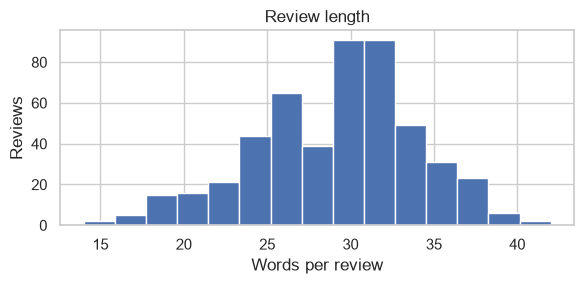

In [5]:
df["n_words"] = df["review_text"].str.split().str.len()
print(df["n_words"].describe().round(1).to_string())
display(df.groupby("rating")["n_words"].mean().round(1).rename("avg words").to_frame().T)

ax = df["n_words"].plot(kind="hist", bins=15, color="#4c72b0", figsize=(6, 3))
ax.set(title="Review length", xlabel="Words per review", ylabel="Reviews")
plt.tight_layout(); plt.show()

Las reseñas son cortas y homogéneas (14–42 palabras, ~29 de media) en todos los niveles de estrellas. Muy lejos del límite de 512 tokens, así que no se cortará nada.

Por último, leemos textos reales. Los números nunca sustituyen a la lectura.

In [6]:
df.groupby("rating").sample(2, random_state=SEED)[["review_id", "rating", "review_text"]]

,review_id,rating,review_text
441,442,1,Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
427,428,1,Regular customer at Harbor House Café here. The coffee tasted burnt. The staff seemed annoyed to be there. It was way too loud to hold a conversation. Disappointing experience overall.
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
338,339,2,Regular customer at Harbor House Café here. The coffee tasted burnt. Nobody checked on us the entire meal. Disappointing experience overall.
479,480,3,"Visited Harbor House Café last weekend. Average sandwiches, nothing to write home about. The staff seemed annoyed to be there. Might give it another shot."
161,162,3,"Visited Harbor House Café last weekend. The menu is fine but a bit repetitive. Service was fine, nothing memorable. It's fine for a quick stop."
323,324,4,"Came to Harbor House Café for a birthday brunch. The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. It's fine for a quick stop."
20,21,4,"The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. This is now my go-to spot."
143,144,5,The music and decor set the perfect mood. Best brunch i've had in months. Five stars without hesitation.
136,137,5,Grabbed a quick coffee at Harbor House Café this morning. Great spot to work or catch up with friends. The team clearly cares about the customers. Five stars without hesitation.


Al leerlas aparece una **estructura**: cada reseña se compone de unas pocas frases recurrentes ("Visited Harbor House Café last weekend.", "Worth every penny.", ...). Contamos las frases más frecuentes por puntuación para ver el vocabulario de cada grupo.

In [7]:
sentences = (
    df.assign(sentence=df["review_text"].str.split(r"(?<=[.!?])\s+", regex=True))
      .explode("sentence")
      .assign(sentence=lambda d: d["sentence"].str.strip())
)
print("Distinct sentences in the whole dataset:", sentences["sentence"].nunique())

for stars in [5, 4, 3, 1]:
    top = sentences[sentences["rating"] == stars]["sentence"].value_counts().head(5)
    print(f"\n{stars}★ most frequent sentences:")
    print(top.to_string())

Distinct sentences in the whole dataset: 69

5★ most frequent sentences:
sentence
This is now my go-to spot.                   84
Will definitely be back!                     74
Five stars without hesitation.               70
Already planning my next visit.              69
The music and decor set the perfect mood.    68

4★ most frequent sentences:
sentence
Service was fine, nothing memorable, but overall a solid experience.     17
The staff were polite but a bit slow, but overall a solid experience.    16
Five stars without hesitation.                                           14
Grabbed a quick coffee at Harbor House Café this morning.                14
Tried Harbor House Café after seeing it recommended online.              13

3★ most frequent sentences:
sentence
Might give it another shot.                         16
The staff were polite but a bit slow.               14
Average sandwiches, nothing to write home about.    13
It's fine for a quick stop.                         13
Th

Solo ~70 frases distintas forman todo el dataset. Hay algo que destaca en las reseñas de 4★: quejas seguidas de **"..., but overall a solid experience"** o **"..., but honestly the food made up for it"**. Son reseñas *mixtas*: una queja real con un veredicto positivo. Medimos cuántas hay.

In [8]:
MIXED_PATTERN = r"but overall a solid experience|but honestly the food made up for it"
df["is_mixed"] = df["review_text"].str.contains(MIXED_PATTERN, regex=True)
display(pd.crosstab(df["rating"], df["is_mixed"], margins=True))

high = df[df["rating"] >= 4]
print(f"Mixed reviews among 4–5★: {high['is_mixed'].sum()} of {len(high)} ({high['is_mixed'].mean():.1%})")

is_mixed,False,True,All
rating,,,
1,12,0,12
2,18,0,18
3,38,0,38
4,3,69,72
5,339,21,360
All,410,90,500


Mixed reviews among 4–5★: 90 of 432 (20.8%)


## 3. Insights y limpieza

**Insights clave**

1. **Las 4.5★ están concentradas arriba:** el 86.4% de las reseñas son de 4–5★. Un modelo que "esté de acuerdo" con las estrellas debería repartir más o menos 86% / 8% / 6% entre positivo / neutral / negativo.
2. **Aproximadamente 1 de cada 5 reseñas bien puntuadas es mixta** (90 de 432): contiene una queja concreta del servicio (esperar 25 min, personal molesto o maleducado, pedido equivocado), pero termina en positivo. Son las que más probablemente confundan al modelo, y además son un tema real y recurrente para el cliente.
3. **Los textos son cortos, limpios y están en inglés** (máximo 42 palabras): sin truncado y sin problemas de idioma para un modelo multilingüe.
4. **El vocabulario es de una cafetería (servicio), no de productos:** personal, esperas, platos, alergias. El modelo que usaremos se entrenó con reseñas de *productos*, así que hay que vigilar el desajuste de dominio.

**Decisiones de limpieza**

- **Textos faltantes o vacíos:** ninguno, no hay nada que eliminar.
- **Pasar a minúsculas, quitar puntuación o stopwords:** *no* se hace, a propósito. Los modelos tipo BERT necesitan la frase completa ("not", "but", "!") para entender el contexto, y el modelo es `uncased` (convierte a minúsculas internamente).
- **Textos duplicados (7):** **se mantienen.** Tienen `review_id` distintos y puntuaciones coherentes, así que son clientes distintos. Eliminarlos cambiaría las 500 reseñas que el cliente va a recibir de verdad.
- **Espacios:** se recortan (paso de seguridad inofensivo, también en `src/app.py`).

In [9]:
df["review_text"] = df["review_text"].str.strip()
df["human_band"] = df["rating"].apply(to_band)
print("Rows after cleaning:", len(df))
(df["human_band"].value_counts(normalize=True).reindex(BAND_ORDER) * 100).round(1).rename("% by human stars").to_frame().T

Rows after cleaning: 500


human_band,Negative,Neutral,Positive
% by human stars,6.0,7.6,86.4


## 4. Plan de acción y elección del modelo

**Modelo:** [`nlptown/bert-base-multilingual-uncased-sentiment`](https://huggingface.co/nlptown/bert-base-multilingual-uncased-sentiment), fijado al commit `8f6f4e3` (`MODEL_REVISION` en `src/utils.py`).

**Por qué este modelo**
- Predice **de 1 a 5 estrellas**, la misma escala que la puntuación humana. Podemos comparar texto y estrellas directamente, reseña por reseña.
- Es preentrenado: con 500 reseñas y sin datos de sentimiento etiquetados, entrenar un modelo propio no sería ni posible ni necesario.
- Multilingüe y `uncased`: robusto ante el idioma y las mayúsculas.
- **Riesgo conocido (insight 4):** se ajustó con reseñas de **productos** y lo aplicamos a reseñas de **servicio**. Planificamos comprobaciones explícitas para esto.

**Mapeo a bandas de sentimiento**

| Predicción del modelo | Banda |
|---|---|
| 1–2 estrellas | Negativo |
| 3 estrellas | Neutral |
| 4–5 estrellas | Positivo |

**Plan**
1. Cargar el modelo **una sola vez**, pasarle las 500 reseñas por lotes y guardar `pred_stars`, `pred_score` (confianza) y `pred_band`.
2. Comparar la distribución predicha con la referencia de 4.5★ (86.4 / 7.6 / 6.0) y localizar los desacuerdos con una tabla de confusión.
3. Investigar los **falsos negativos** (modelo 1–2★, humano 4–5★) y poner a prueba una hipótesis.
4. Revisar a mano una muestra estratificada de 18 predicciones.
5. Traducir todo a una conclusión útil para la account manager.

**Reglas de integración:** `pipeline()` descarga los pesos a la caché local de Hugging Face (nunca se suben al repo); el nombre y la versión del modelo están fijados; el modelo se carga una sola vez antes de la inferencia.

## 5. Inferencia sobre las 500 reseñas

El modelo se carga **una sola vez** aquí y se reutiliza para todas las reseñas (y para las pruebas de la sección 7).

In [10]:
print(f"Model: {MODEL_NAME}\nRevision (pinned): {MODEL_REVISION}")
clf = load_classifier()  # <- the only place the model is loaded

max_tokens = max(len(clf.tokenizer(t)["input_ids"]) for t in df["review_text"])
print(f"Longest review: {max_tokens} tokens (limit 512) -> no truncation needed")

Model: nlptown/bert-base-multilingual-uncased-sentiment
Revision (pinned): 8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  12%|█▏        | 24/201 [00:00<00:00, 200.84it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1297.51it/s]

Longest review: 59 tokens (limit 512) -> no truncation needed


In [11]:
df["pred_stars"], df["pred_score"] = predict(clf, df["review_text"], batch_size=16)
df["pred_band"] = df["pred_stars"].apply(to_band)

print("Reviews with a prediction:", df["pred_stars"].notna().sum(), "/", len(df))
df[["review_id", "rating", "pred_stars", "pred_score", "pred_band", "review_text"]].head()

Reviews with a prediction: 500 / 500


,review_id,rating,pred_stars,pred_score,pred_band,review_text
0,1,5,5,0.7170,Positive,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,5,0.9822,Positive,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.
2,3,5,5,0.6623,Positive,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.
3,4,5,5,0.9895,Positive,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,5,0.9829,Positive,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


Todas las reseñas tienen ya estrellas predichas, una puntuación de confianza y una banda de sentimiento. (La misma lógica se ejecuta en `src/app.py`, que escribe `data/processed/reviews_with_sentiment.csv`.)

## 6. Desglose vs el promedio de 4.5★

Primero las cifras principales: qué porcentaje de reseñas *se lee* positivo, neutral y negativo, junto a lo que dicen las estrellas.

,Model (text),Human stars,Gap (pts)
Negative,9.4,6.0,3.4
Neutral,8.2,7.6,0.6
Positive,82.4,86.4,-4.0


Average stars - human: 4.50 | model (text): 4.40


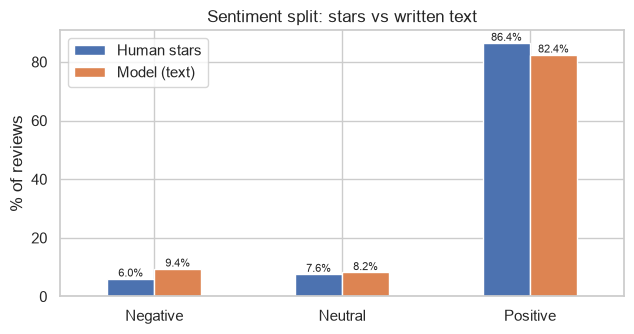

In [12]:
comparison = pd.DataFrame({
    "Model (text)": df["pred_band"].value_counts(normalize=True),
    "Human stars": df["human_band"].value_counts(normalize=True),
}).reindex(BAND_ORDER).mul(100).round(1)
comparison["Gap (pts)"] = (comparison["Model (text)"] - comparison["Human stars"]).round(1)
display(comparison)

print(f"Average stars - human: {df['rating'].mean():.2f} | model (text): {df['pred_stars'].mean():.2f}")

ax = comparison[["Human stars", "Model (text)"]].plot(kind="bar", rot=0, figsize=(6.5, 3.5), color=["#4c72b0", "#dd8452"])
ax.set(title="Sentiment split: stars vs written text", ylabel="% of reviews", xlabel="")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=8)
plt.tight_layout(); plt.show()

**Cerca, pero no idéntico.** El texto se lee un 82.4% positivo frente al 86.4% según las estrellas, y la media del modelo es 4.40★ frente a 4.50★. La diferencia se concentra en la banda **negativa** (+3.4 puntos). Para saber *de dónde* viene, cruzamos la banda humana con la del modelo (tabla de confusión): la diagonal son los acuerdos y todo lo demás, desacuerdos.

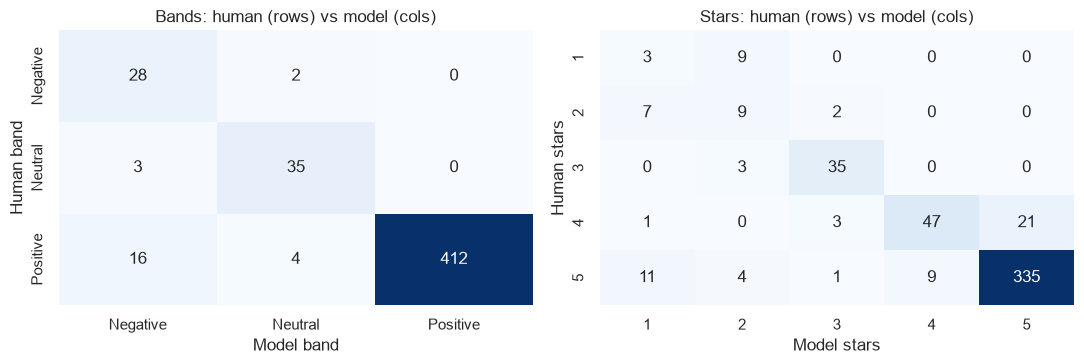

Band agreement: 95.0%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
band_ct = pd.crosstab(df["human_band"], df["pred_band"]).reindex(index=BAND_ORDER, columns=BAND_ORDER, fill_value=0)
sns.heatmap(band_ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Bands: human (rows) vs model (cols)", xlabel="Model band", ylabel="Human band")

star_ct = pd.crosstab(df["rating"], df["pred_stars"])
sns.heatmap(star_ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set(title="Stars: human (rows) vs model (cols)", xlabel="Model stars", ylabel="Human stars")
plt.tight_layout(); plt.show()

agree = (df["human_band"] == df["pred_band"]).mean()
print(f"Band agreement: {agree:.1%}")

- El modelo coincide con la banda humana en el **95%** de las reseñas.
- El mayor bloque de desacuerdo son **16 reseñas con 4–5★ que el modelo considera negativas**. Eso por sí solo explica los puntos negativos de más. Pequeños restos: 4 positivas→neutrales, 3 neutrales→negativas y 2 negativas→neutrales.
- Llama la atención que las 90 reseñas **mixtas** (queja + veredicto positivo) se leen mayoritariamente bien, como positivas. Lo comprobamos antes de culparlas:

In [14]:
pd.crosstab(df.loc[df["rating"] >= 4, "is_mixed"], df.loc[df["rating"] >= 4, "pred_band"], margins=True) \
  .rename(index={True: "mixed (complaint + 'but...')", False: "purely positive"})

pred_band,Negative,Neutral,Positive,All
is_mixed,,,,
purely positive,14,0,328,342
mixed (complaint + 'but...'),2,4,84,90
All,16,4,412,432


Las reseñas mixtas **no** son el problema principal: solo un par se vuelven negativas. Entonces, ¿qué tienen en común los 16 falsos negativos?

## 7. Falsos negativos

Definición: el modelo predice **1–2★** pero la persona puso **4–5★**. Si se los presentáramos al cliente como "reseñas negativas", estaríamos equivocándonos.

In [15]:
fn = df[(df["pred_stars"] <= 2) & (df["rating"] >= 4)]
print(f"False negatives: {len(fn)} ({len(fn) / (df['rating'] >= 4).sum():.1%} of the 4–5★ reviews)")
fn[["review_id", "rating", "pred_stars", "pred_score", "review_text"]]

False negatives: 16 (3.7% of the 4–5★ reviews)


,review_id,rating,pred_stars,pred_score,review_text
13,14,4,1,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.2679,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.3247,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.2751,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.3492,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."
253,254,5,1,0.3641,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,0.4091,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,0.6077,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


Al leerlas, son **claramente entusiastas** ("Already planning my next visit", "This is now my go-to spot"). Aun así, hay dos frases que aparecen una y otra vez. Comparamos con qué frecuencia aparece cada frase en los falsos negativos frente al resto de reseñas de 4–5★.

In [16]:
high_sent = sentences[sentences["rating"] >= 4].copy()
high_sent["is_fn"] = high_sent["review_id"].isin(fn["review_id"])

share = (high_sent.groupby(["sentence", "is_fn"])["review_id"].nunique().unstack(fill_value=0)
         .div([(~df.loc[df["rating"] >= 4, "review_id"].isin(fn["review_id"])).sum(), len(fn)], axis=1)
         .mul(100).round(1))
share.columns = ["% of other 4–5★", "% of false negatives"]
share["lift"] = (share["% of false negatives"] - share["% of other 4–5★"]).round(1)
share.sort_values("lift", ascending=False).head(6)

,% of other 4–5★,% of false negatives,lift
sentence,,,
Every dish was bursting with flavor.,7.0,75.0,68.0
Already planning my next visit.,15.4,68.8,53.4
Stopped by Harbor House Café for the first time.,13.2,37.5,24.3
Tried Harbor House Café after seeing it recommended online.,14.9,37.5,22.6
They went out of their way to accommodate my allergy.,8.2,25.0,16.8
The team clearly cares about the customers.,11.1,18.8,7.7


Dominan dos frases:

- **"Every dish was bursting with flavor."** aparece en 12 de los 16 falsos negativos (75%), frente al 7% del resto de reseñas positivas.
- **"They went out of their way to accommodate my allergy."** aparece en los otros 4.

Entre las dos cubren **los 16**. **Hipótesis (cambio de dominio):** el modelo aprendió con reseñas de *productos*, donde "**bursting**" suele significar que algo se rompió o se derramó ("the bag arrived bursting") y "**allergy**" que el producto provocó una reacción. En una reseña de cafetería, ambas son elogios. El modelo reacciona a la palabra, no a su significado en este contexto.

Una hipótesis hay que ponerla a prueba. Tomamos las 16 reseñas, cambiamos **solo** la frase sospechosa por un sinónimo neutro y volvemos a pasarlas por el mismo modelo (ya cargado):

In [17]:
TRIGGERS = {
    "Every dish was bursting with flavor.": "Every dish was full of flavor.",
    "They went out of their way to accommodate my allergy.": "They were very accommodating.",
}

def swap_triggers(text):
    for old, new in TRIGGERS.items():
        text = text.replace(old, new)
    return text

test = fn[["review_id", "rating", "pred_stars"]].copy()
test["stars_after_swap"], _ = predict(clf, fn["review_text"].apply(swap_triggers))
test["band_after_swap"] = test["stars_after_swap"].apply(to_band)
display(test)
print(f"Back to Positive after swapping one sentence: {(test['band_after_swap'] == 'Positive').sum()} / {len(test)}")

# The trigger sentences on their own:
for s in list(TRIGGERS) + list(TRIGGERS.values()):
    r = clf(s)[0]
    print(f"{r['label']:>8} ({r['score']:.2f})  <- {s}")

,review_id,rating,pred_stars,stars_after_swap,band_after_swap
13,14,4,1,5,Positive
14,15,5,1,5,Positive
72,73,5,1,5,Positive
86,87,5,1,5,Positive
137,138,5,2,4,Positive
199,200,5,2,5,Positive
203,204,5,1,4,Positive
253,254,5,1,5,Positive
269,270,5,1,5,Positive
321,322,5,1,5,Positive


Back to Positive after swapping one sentence: 16 / 16
  1 star (0.67)  <- Every dish was bursting with flavor.
  1 star (0.44)  <- They went out of their way to accommodate my allergy.
 5 stars (0.61)  <- Every dish was full of flavor.
 5 stars (0.58)  <- They were very accommodating.


**La prueba confirma la hipótesis:** cambiar una sola frase devuelve **las 16** reseñas a 4–5★. Por separado, las dos frases sospechosas reciben **1★**, mientras que sus sinónimos ("full of flavor", "very accommodating") reciben **5★**. El resto de cada reseña siempre fue positivo: el modelo reaccionaba a una palabra.

¿Cuánto nos afecta en general? Estas frases no siempre cambian la clasificación, pero la hacen mucho más probable:

In [18]:
rows = []
for phrase in TRIGGERS:
    has = df["review_text"].str.contains(phrase, regex=False)
    rows.append({"phrase": phrase, "reviews containing it": has.sum(),
                 "predicted Negative": (df.loc[has, "pred_band"] == "Negative").sum(),
                 "% Negative": round((df.loc[has, "pred_band"] == "Negative").mean() * 100, 1)})
no_trigger = ~df["review_text"].str.contains("|".join(map(lambda p: p.replace(".", r"\."), TRIGGERS)), regex=True)
hi_clean = df[no_trigger & (df["rating"] >= 4)]
rows.append({"phrase": "(4–5★ reviews with neither phrase)", "reviews containing it": len(hi_clean),
             "predicted Negative": (hi_clean["pred_band"] == "Negative").sum(),
             "% Negative": round((hi_clean["pred_band"] == "Negative").mean() * 100, 1)})
pd.DataFrame(rows)

,phrase,reviews containing it,predicted Negative,% Negative
0,Every dish was bursting with flavor.,41,12,29.3
1,They went out of their way to accommodate my allergy.,38,4,10.5
2,(4–5★ reviews with neither phrase),353,0,0.0


Sin esas dos frases, el modelo no considera negativa **ninguna** de las reseñas de 4–5★. Los falsos negativos vienen por completo de esas dos frases.

**¿Hay alguna señal de alerta que podamos usar en el futuro?** La confianza del modelo (`pred_score`):

In [19]:
df["is_fn"] = df["review_id"].isin(fn["review_id"])
display(df.groupby("is_fn")["pred_score"].describe()[["mean", "50%", "max"]].round(2)
          .rename(index={False: "other reviews", True: "false negatives"}))

low_conf = df["pred_score"] < 0.5
print(f"False negatives with confidence < 0.5: {(df['is_fn'] & low_conf).sum()} / {len(fn)}")
print(f"Reviews with confidence < 0.5 overall: {low_conf.sum()} / {len(df)} -> queue for a quick human check")

,mean,50%,max
is_fn,,,
other reviews,0.71,0.71,0.99
false negatives,0.38,0.36,0.61


False negatives with confidence < 0.5: 15 / 16
Reviews with confidence < 0.5 overall: 73 / 500 -> queue for a quick human check


Los falsos negativos tienen una **confianza claramente baja** (mediana ≈ 0.36). Enviar las predicciones con poca confianza (< 0.5) a una revisión humana rápida (73 reseñas, ~15%) detectaría 15 de los 16.

**Resumen del análisis de falsos negativos**
- **Qué:** 16 reseñas entusiastas (4–5★) etiquetadas como negativas, el 3.7% de las reseñas positivas.
- **Patrón compartido:** todas contienen *"bursting with flavor"* o *"accommodate my allergy"*.
- **Por qué (hipótesis, puesta a prueba):** cambio de dominio. Palabras que en reseñas de productos señalan un defecto son elogios en reseñas de restaurantes. Cambiar esa única frase corrige los 16.
- **Señal de alerta:** baja confianza del modelo.

## 8. Revisión manual (18 reseñas)

Las métricas comparan el modelo con las estrellas, pero las estrellas no son el texto. Así que leemos nosotros mismos algunas predicciones. La muestra es **estratificada** (unas cuantas de cada situación, no solo al azar, porque saldrían casi solo reseñas de 5★):
positivas claras (4), positivas mixtas (4), neutrales (3), negativas en las que ambos coinciden (3) y falsos negativos (4).

In [20]:
groups = {
    "clear positive": df[(df["pred_band"] == "Positive") & (df["human_band"] == "Positive") & ~df["is_mixed"]],
    "mixed positive": df[(df["rating"] >= 4) & df["is_mixed"]],
    "neutral": df[df["pred_band"] == "Neutral"],
    "negative (agree)": df[(df["pred_band"] == "Negative") & (df["human_band"] == "Negative")],
    "false negative": fn,
}
n_per_group = {"clear positive": 4, "mixed positive": 4, "neutral": 3, "negative (agree)": 3, "false negative": 4}
sample = pd.concat([g.sample(n_per_group[k], random_state=SEED).assign(group=k) for k, g in groups.items()])

# My own reading of each text (written after reading every review below)
MY_READING = {
    353: ("Positive", "Correct. Warm, personal service."),
    174: ("Positive", "Correct."),
    381: ("Positive", "Correct."),
    12:  ("Positive", "Correct."),
    250: ("Positive", "Correct. 25-min wait mentioned, but the food 'made up for it'."),
    116: ("Positive", "Correct-ish. Wait complaint + lukewarm closing; 4★ is fair."),
    322: ("Positive", "WRONG (1★). Complains about staff, but positive overall; 'bursting' trigger."),
    395: ("Positive", "Correct. Mixed but positive."),
    326: ("Neutral",  "Correct. Lukewarm on everything."),
    162: ("Neutral",  "Correct."),
    127: ("Neutral",  "Debatable. 'Staff seemed annoyed' leans negative; neutral is acceptable (low confidence 0.45)."),
    123: ("Negative", "Correct band (2★ vs 1★ doesn't matter for the band)."),
    442: ("Negative", "Correct band."),
    115: ("Negative", "Correct."),
    14:  ("Positive", "WRONG (1★). Clearly enthusiastic; 'bursting' trigger."),
    15:  ("Positive", "WRONG (1★). Clearly enthusiastic; 'bursting' trigger."),
    200: ("Positive", "WRONG (2★). Clearly enthusiastic; 'bursting' trigger."),
    474: ("Positive", "WRONG (1★). Clearly enthusiastic; 'bursting' trigger."),
}
sample["my_reading"] = sample["review_id"].map(lambda i: MY_READING.get(i, (None, None))[0])
sample["note"] = sample["review_id"].map(lambda i: MY_READING.get(i, (None, None))[1])
sample["model_ok"] = sample["my_reading"] == sample["pred_band"]

sample[["review_id", "group", "rating", "pred_stars", "pred_score", "pred_band", "my_reading", "model_ok", "note", "review_text"]]

,review_id,group,rating,pred_stars,pred_score,pred_band,my_reading,model_ok,note,review_text
352,353,clear positive,5,5,0.8821,Positive,Positive,True,"Correct. Warm, personal service.",Visited Harbor House Café last weekend. Our server remembered our names by the second visit. The music and decor set the perfect mood. Highly recommend to anyone in the area.
173,174,clear positive,5,5,0.6313,Positive,Positive,True,Correct.,Came to Harbor House Café for a birthday brunch. The staff were warm and attentive. The food was absolutely delicious. Reasonably priced for the quality. This is now my go-to spot.
380,381,clear positive,5,5,0.6838,Positive,Positive,True,Correct.,Came to Harbor House Café for a birthday brunch. The coffee was rich and perfectly brewed. Loved the natural light and the plants everywhere. Already planning my next visit.
11,12,clear positive,5,5,0.7131,Positive,Positive,True,Correct.,Regular customer at Harbor House Café here. The pastries were incredible. Service was fast and friendly. Great value for what you get. Will definitely be back!
249,250,mixed positive,5,5,0.6231,Positive,Positive,True,"Correct. 25-min wait mentioned, but the food 'made up for it'.","Regular customer at Harbor House Café here. Fresh ingredients you can really taste. We waited 25 minutes just to get water, but honestly the food made up for it. Highly recommend to anyone in the area."
115,116,mixed positive,4,4,0.6654,Positive,Positive,True,Correct-ish. Wait complaint + lukewarm closing; 4★ is fair.,"Came to Harbor House Café for a birthday brunch. The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. Wouldn't go out of my way, but wouldn't avoid it either."
321,322,mixed positive,5,1,0.6077,Negative,Positive,False,"WRONG (1★). Complains about staff, but positive overall; 'bursting' trigger.","Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"
394,395,mixed positive,4,4,0.7036,Positive,Positive,True,Correct. Mixed but positive.,"The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. Might give it another shot."
325,326,neutral,3,3,0.6682,Neutral,Neutral,True,Correct. Lukewarm on everything.,"Came to Harbor House Café for a birthday brunch. The menu is fine but a bit repetitive. Average service, no complaints. Wouldn't go out of my way, but wouldn't avoid it either."
161,162,neutral,3,3,0.6918,Neutral,Neutral,True,Correct.,"Visited Harbor House Café last weekend. The menu is fine but a bit repetitive. Service was fine, nothing memorable. It's fine for a quick stop."


In [21]:
print(f"I agree with the model in {sample['model_ok'].sum()} of {len(sample)} reviews.")
sample.groupby("group", sort=False)["model_ok"].agg(["sum", "count"]).rename(columns={"sum": "agree", "count": "reviewed"})

I agree with the model in 13 of 18 reviews.


,agree,reviewed
group,,
clear positive,4,4
mixed positive,3,4
neutral,3,3
negative (agree),3,3
false negative,0,4


**Qué nos dice la revisión manual**
- En las positivas claras, las neutrales, las negativas y la mayoría de las mixtas, el modelo lee el texto **como lo haría una persona**.
- Todos los errores que encontré son reseñas con **"bursting with flavor"**: el mismo fallo de la sección 7, ahora confirmado leyendo, no solo comparando con las estrellas.
- Un caso discutible (reseña 127): una queja de personal molesto etiquetada como neutral. Es razonable, y la baja confianza del modelo lo señala.
- **No** encontré ningún caso en el que el texto sea de verdad más negativo de lo que indican las estrellas. Las estrellas son honestas.

Último paso antes de concluir: si corregimos los 16 falsos negativos confirmados y los devolvemos a positivo, ¿cómo queda la distribución frente a las estrellas?

In [22]:
df["band_adjusted"] = df["pred_band"].where(~df["is_fn"], "Positive")
final = pd.DataFrame({
    "Human stars": df["human_band"].value_counts(normalize=True),
    "Model, raw": df["pred_band"].value_counts(normalize=True),
    "Model, after fixing false negatives": df["band_adjusted"].value_counts(normalize=True),
}).reindex(BAND_ORDER).mul(100).round(1)
final

,Human stars,"Model, raw","Model, after fixing false negatives"
Negative,6.0,9.4,6.2
Neutral,7.6,8.2,8.2
Positive,86.4,82.4,85.6


## 9. Conclusiones

**Para la account manager, en palabras simples**

1. **Las reseñas se leen tan positivas como dicen las estrellas.** De 500 reseñas, alrededor del **86% se lee positivo, el 8% neutral y el 6% negativo**, lo que coincide casi exactamente con un promedio de 4.5★.
2. **El resultado bruto de la herramienta mostraba una pequeña diferencia** (82% positivo y 9% negativo). Esa diferencia **no es real**: viene de **16 reseñas entusiastas** que la herramienta leyó mal por culpa de dos frases, *"bursting with flavor"* y *"accommodate my allergy"*. La herramienta se creó para reseñas de productos, donde esas palabras suelen significar que algo salió mal. **No le mostréis al cliente la cifra bruta de "9% negativo".**
3. **Un matiz real que vale la pena compartir:** aproximadamente **1 de cada 5 reseñas positivas menciona un problema de servicio** (esperas de 25 minutos, personal que parecía molesto o maleducado, pedidos equivocados), aunque el cliente se fue contento. Es un tema recurrente y solucionable, y un punto útil y honesto para plantearle al cliente.
4. **Las reseñas realmente negativas (~6%)** hablan de esos mismos temas y además de la calidad de la comida (café quemado, huevos fríos, raciones pequeñas).

**Cómo lo sabemos (el método en una línea):** modelo de sentimiento preentrenado `nlptown` (versión fijada), comparado reseña por reseña con las estrellas humanas, con todos los desacuerdos investigados, el patrón de error principal puesto a prueba y 18 predicciones revisadas a mano (13 de 18 correctas; los 5 errores eran la misma frase conocida).

**Limitaciones**
- El modelo se entrenó con reseñas de productos, así que tiene puntos ciegos con el vocabulario de hostelería (demostrado arriba).
- Las reseñas siguen plantillas muy marcadas (~70 frases distintas), así que una sola frase mal leída afecta a muchas reseñas a la vez.
- La revisión manual cubre 18 reseñas: confirma el patrón, pero no es una auditoría completa.

**Recomendaciones para la entrega de la próxima semana**
- Presentar la distribución ajustada (≈86 / 8 / 6) y el tema de los problemas de servicio, no las cifras brutas del modelo.
- Antes de la entrega, enviar las predicciones con poca confianza (score < 0.5) a una revisión humana rápida. Son unas 73 reseñas (~15%) y detecta 15 de los 16 errores.
- Para un uso continuado, valorar un modelo de sentimiento entrenado con reseñas de restaurantes o servicios.